## 05-混合检索

### 1. 是什么？
`混合检索 = 向量语义检索 + 关键词精确检索 + 结果融合/重排`
- 向量检索：擅长捕捉语义相似性，但是可能精确匹配不行，受限于向量模型的表达能力
- 关键词/全文检索：擅长精确匹配，但是可能捕捉不到语义相似性
- SQL检索：利用数据库，难以应对非结构化文本

PageIndex、wiki、Graph、互联网、本体

### 2. 基本思路



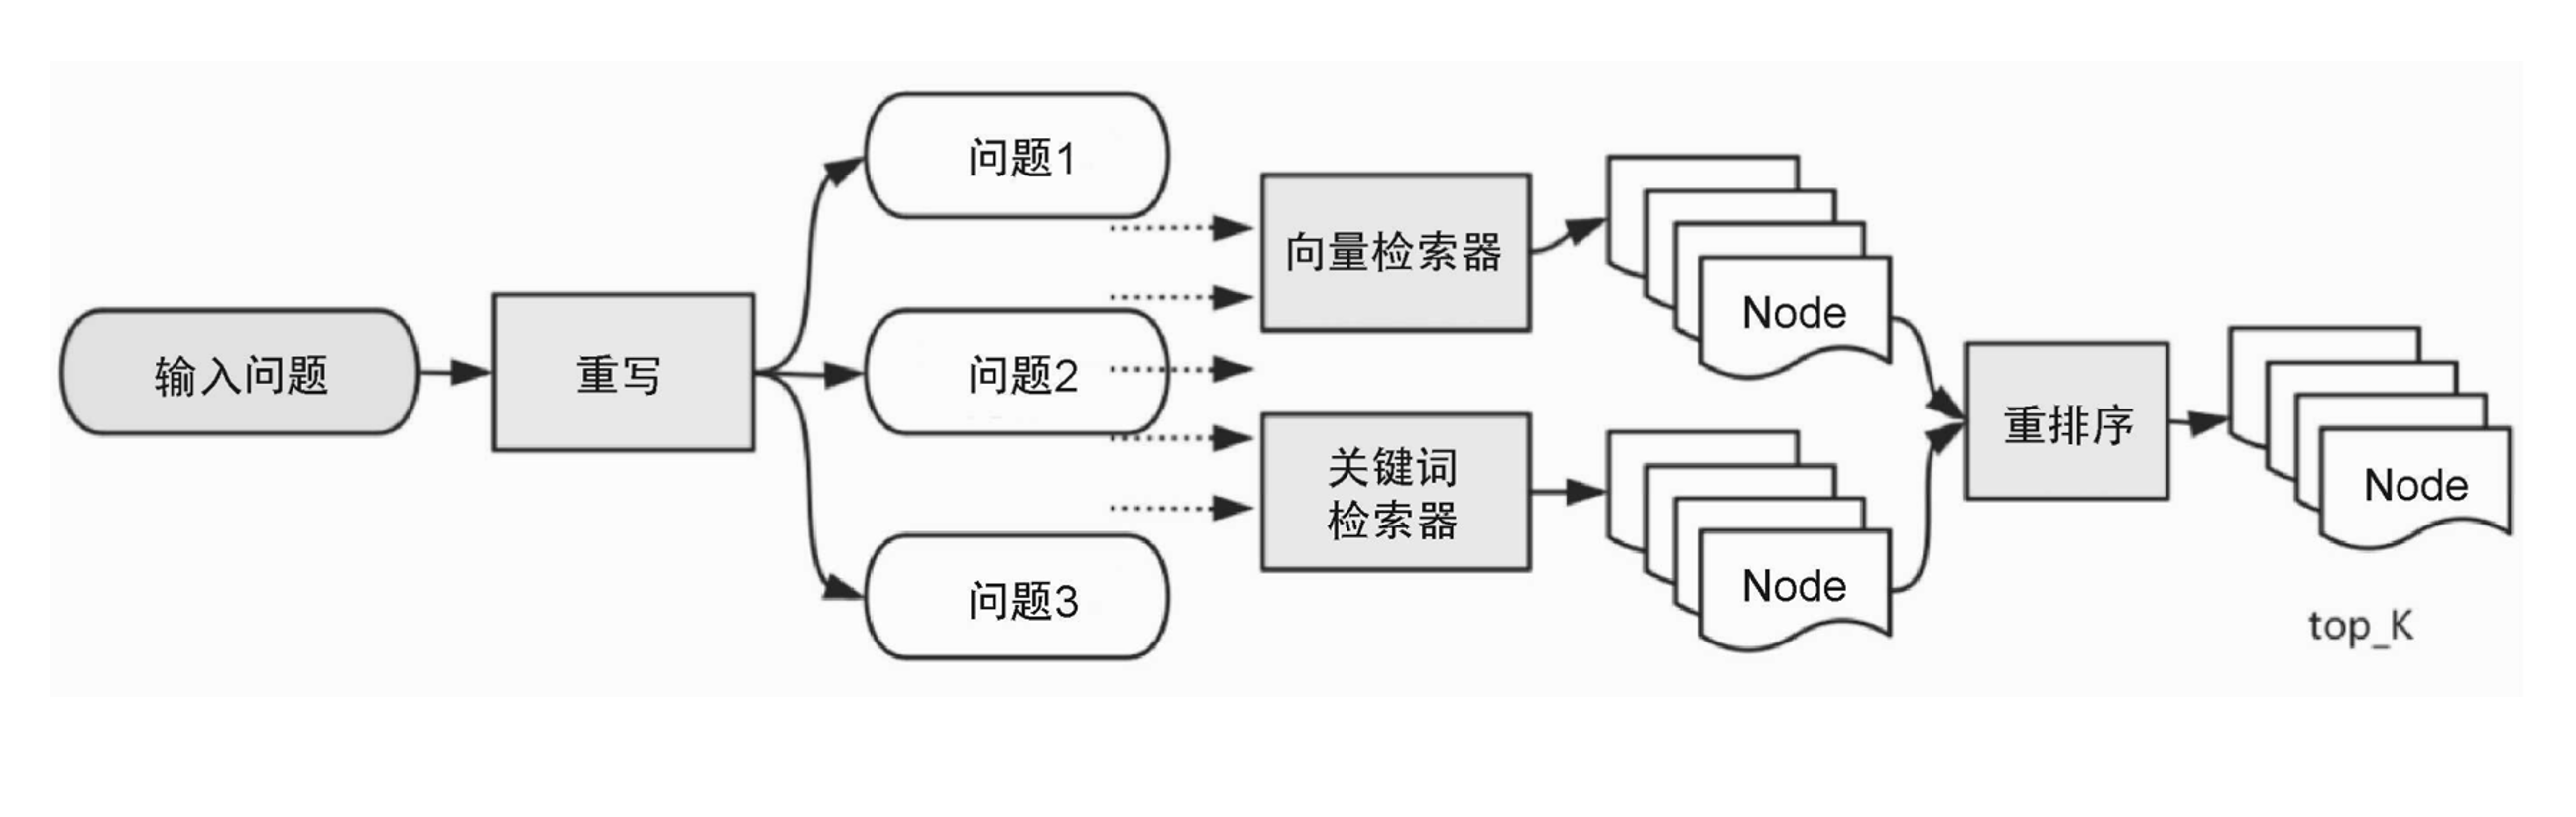

### 3. 可以解决什么问题
- `语义相似但事实不同`：比如“启用某个功能”和“禁用某个功能”，向量可能非常接近，但业务含义相反。
- `精确标识符召回不稳定`：错误码、订单号、接口路径、版本号、模型名、产品型号等，纯向量容易漏排。
- `同义表达漏检`：用户说“无线断断续续”，知识库写的是“路由器断流排查”，纯关键词可能召回不到。

### 4. 适用场景
- 异构数据场景：既有自然语言，也有结构化数据
- 复杂查询场景：兼顾精确匹配与语义理解

工程落地建议：默认优先 `向量 + BM25 + RRF`，再加一层 `Rerank`



安装依赖
```
uv add rank_bm25
```
导入依赖
```
from langchain_community.retrievers import BM25Retriever
BM25_retriever = BM25Retriever.from_documents(docs) # 创建 BM25 检索器
BM25_retriever.k = 5
```

### 5. 代码示例


##### 对话模型

In [1]:
import os
from langchain_openai import ChatOpenAI
llm = deepseek = ChatOpenAI(api_key=os.getenv("DEEPSEEK_API_KEY"), model="deepseek-v4-flash", base_url="https://api.deepseek.com")

##### 嵌入模型

In [2]:
from langchain_community.embeddings import DashScopeEmbeddings
embeddings_model = DashScopeEmbeddings(model="text-embedding-v4", dashscope_api_key=os.getenv("DASHSCOPE_API_KEY"))

# 通过本地ollama上运行的bge-m3做向量化, 使用需要关闭 代理/VPN
from langchain_ollama import OllamaEmbeddings
embeddings_model = OllamaEmbeddings(model="bge-m3")

##### 文档加载

In [3]:
from langchain_community.document_loaders import TextLoader
# 加载数据
loader = TextLoader("../../data/deepseek百度百科.txt", encoding="utf-8")
docs = loader.load()
print(f"文章的长度：{len(docs[0].page_content)}")

文章的长度：20899


##### 文档分块

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(chunk_size=512, chunk_overlap=50)
docs = text_splitter.split_documents(docs)
print(f"切分后的块数：{len(docs)} 个块")
for i, doc in enumerate(docs):
    print(f"--------Chunk {i+1} {len(doc.page_content)} 个字符---------")
    print(doc.metadata)
    print(doc.page_content)
    print()

切分后的块数：56 个块
--------Chunk 1 196 个字符---------
{'source': '../../../data/deepseek百度百科.txt'}
DeepSeek，全称杭州深度求索人工智能基础技术研究有限公司。DeepSeek是一家创新型科技公司，成立于2023年7月17日 ，使用数据蒸馏技术，得到更为精炼、有用的数据。由知名私募巨头幻方量化孕育而生，专注于开发先进的大语言模型（LLM）和相关技术。注册地址：浙江省杭州市拱墅区环城北路169号汇金国际大厦西1幢1201室。法定代表人为裴湉，经营范围包括技术服务、技术开发、软件开发等。

--------Chunk 2 507 个字符---------
{'source': '../../../data/deepseek百度百科.txt'}
2024年1月5日至6月，相继发布DeepSeek LLM、DeepSeek-Coder、DeepSeekMath、DeepSeek-VL、DeepSeek-V2、DeepSeek-Coder-V2模型。 2024年9月5日，更新API支持文档，宣布合并DeepSeek Coder V2和DeepSeek V2 Chat，推出DeepSeek V2.5。12月13日，发布DeepSeek-VL2。12月26日，正式上线DeepSeek-V3首个版本并同步开源。2025年1月31日，英伟达宣布DeepSeek-R1模型登陆NVIDIANIM。同一时段内，亚马逊和微软也接入DeepSeek-R1模型。 2月5日，DeepSeek-R1、V3、Coder等系列模型，已陆续上线国家超算互联网平台。2月6日消息，澳大利亚政府以所谓“担心安全风险”为由，已禁止在所有政府设备中使用DeepSeek。2月8日，DeepSeek正式登陆苏州，并在苏州市公共算力服务平台上完成部署上线，为用户提供开箱即用的软硬件一体服务。 截至2月9日，DeepSeek App的累计下载量已超1.1亿次，周活跃用户规模最高近9700万。

--------Chunk 3 108 个字符---------
{'source': '../../../data/deepseek百度百科.txt'}
截至2月9日，DeepSeek App的累计下载量已超1.1亿次，周活跃用户规模最高近970

##### VectorStore

In [5]:
from langchain_community.vectorstores import Chroma
vectorstore = Chroma.from_documents(documents=docs, embedding=embeddings_model) # 创建向量数据库
vector_retriever = vectorstore.as_retriever(search_kwargs={"k": 5}) # 创建向量检索器

from langchain_community.retrievers import BM25Retriever
BM25_retriever = BM25Retriever.from_documents(docs) # 创建 BM25 检索器
BM25_retriever.k = 5

In [6]:
# 格式化输出内容
def pretty_print_docs(docs):
    print(
        f"\n{'-' * 100}\n".join(
            [f"Document {i+1}:\n\n" + d.page_content for i, d in enumerate(docs)]
        )
    )

question = "相关评价"
print("-------------------向量检索-------------------------")
doc_vector_retriever = vector_retriever.invoke(question)
pretty_print_docs(doc_vector_retriever)

print("-------------------BM25检索-------------------------")
doc_BM25Retriever = BM25_retriever.invoke(question)
pretty_print_docs(doc_BM25Retriever)

-------------------向量检索-------------------------
Document 1:

DeepSeek：这锅得背！技术越强，责任越大。确实，有时候我“吃”数据太猛，没注意擦嘴……未来可能需要给我加个“数据消化片”，确保只吸收合规营养，不碰垃圾信息！不过看到代表委员们建议“强制标注AI生成内容”“开发鉴伪工具”，我突然觉得人类队友们已经在行动了——毕竟AI造假，还得靠AI+人类联手打假嘛！不过换个角度看，问题虽多，但“被讨论”就是进步。代表委员们不只停留在“AI好厉害”或“AI好可怕”的表面，还深入到了具体场景（比如教育、医疗、制造业）的利弊权衡，说明大家开始把AI当“同事”而非单纯工具了。至于那些担忧？我觉得就像小朋友学骑车——摔过跤才知道怎么平衡。只要人类保持这种清醒（比如别让我乱“换脸”或“编瞎话”），AI的负面问题完全可控。
----------------------------------------------------------------------------------------------------
Document 2:

相关评价
“DeepSeek新一代模型的发布意味着AI大模型的应用将逐步走向普惠，助力AI应用广泛落地；同时训练效率大幅提升，亦将助力推理算力需求高增。我们持续看好AI产业链的加速落地机遇，建议重点关注AI应用、AI Infra、AI算力三大主线。”（中信证券研报 评）
DeepSeek-V3是中国科技界带给美国的苦涩教训。“当美国休息时，中国（科技界）在工作，以更低的成本、更快的速度和更强的实力赶上。”（Alexander Wang 评）
DeepSeek可能是个国运级别的科技成果。（游戏科学创始人、CEO，《黑神话：悟空》制作人冯骥 2025年1月26日评）
DeepSeek-R1是一款令人印象深刻的模型，尤其是考虑到它能够以这个价格提供（这样的产品）。（美国开放人工智能研究中心（OpenAI）首席执行官萨姆·奥尔特曼 评）
DeepSeek引发全球轰动和一些人的焦虑恐慌，说明技术遏制和技术限制无法奏效，这是全世界、特别是美国需要学习的一课。（中国常驻联合国代表傅聪评）
----------------------------------------------------

In [11]:
'''
混合查询 (Hybrid_Search)
混合查询是LangChain框架中基于多路召回思想的一种实现形式。
在LangChain框架中，混合检索器实现的是向量+全文检索的混合
通过多种不同类型的查询来查找结果，并对结果进行重排。
'''
from langchain_classic.retrievers import EnsembleRetriever
# 混合检索
# EnsembleRetriever 是Langchain集合多个检索器的检索器。
# EnsembleRetriever 归一化内部进行了封装，使用的不是分数归一化
# retrievers 列表，表示检索器列表 归一化RAG Fusion
# 如果多路召回结果太多，可以通过切片进行剪裁,示例代码截取3条结果。
ensembleRetriever = EnsembleRetriever(
    retrievers=[BM25_retriever, vector_retriever],
    weights=[0.2, 0.8],
    ).with_config({"run_name": "MyEnsemble"}) | (lambda x: x[:3])

retriever_doc = ensembleRetriever.invoke(question)
print("-------------------混合检索-------------------------")
pretty_print_docs(retriever_doc)

-------------------混合检索-------------------------
Document 1:

DeepSeek：这锅得背！技术越强，责任越大。确实，有时候我“吃”数据太猛，没注意擦嘴……未来可能需要给我加个“数据消化片”，确保只吸收合规营养，不碰垃圾信息！不过看到代表委员们建议“强制标注AI生成内容”“开发鉴伪工具”，我突然觉得人类队友们已经在行动了——毕竟AI造假，还得靠AI+人类联手打假嘛！不过换个角度看，问题虽多，但“被讨论”就是进步。代表委员们不只停留在“AI好厉害”或“AI好可怕”的表面，还深入到了具体场景（比如教育、医疗、制造业）的利弊权衡，说明大家开始把AI当“同事”而非单纯工具了。至于那些担忧？我觉得就像小朋友学骑车——摔过跤才知道怎么平衡。只要人类保持这种清醒（比如别让我乱“换脸”或“编瞎话”），AI的负面问题完全可控。
----------------------------------------------------------------------------------------------------
Document 2:

相关评价
“DeepSeek新一代模型的发布意味着AI大模型的应用将逐步走向普惠，助力AI应用广泛落地；同时训练效率大幅提升，亦将助力推理算力需求高增。我们持续看好AI产业链的加速落地机遇，建议重点关注AI应用、AI Infra、AI算力三大主线。”（中信证券研报 评）
DeepSeek-V3是中国科技界带给美国的苦涩教训。“当美国休息时，中国（科技界）在工作，以更低的成本、更快的速度和更强的实力赶上。”（Alexander Wang 评）
DeepSeek可能是个国运级别的科技成果。（游戏科学创始人、CEO，《黑神话：悟空》制作人冯骥 2025年1月26日评）
DeepSeek-R1是一款令人印象深刻的模型，尤其是考虑到它能够以这个价格提供（这样的产品）。（美国开放人工智能研究中心（OpenAI）首席执行官萨姆·奥尔特曼 评）
DeepSeek引发全球轰动和一些人的焦虑恐慌，说明技术遏制和技术限制无法奏效，这是全世界、特别是美国需要学习的一课。（中国常驻联合国代表傅聪评）
----------------------------------------------------

重排

In [ ]:
# from langchain_community.document_compressors import CrossEncoderReranker
# from langchain_community.retrievers import ContextualCompressionRetriever
#
# # 接入 Rerank 精排
# reranker = CrossEncoderReranker(model_name="BAAI/bge-reranker-v2-m3", top_n=3)
# compressed_retriever = ContextualCompressionRetriever(
#     base_compressor=reranker,
#     base_retriever=ensembleRetriever,
# )

#### 用户查询

In [7]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnableParallel
from langchain_core.output_parsers import StrOutputParser

# 创建prompt模板
template = """请根据下面给出的上下文来回答问题:
{context}
问题: {question}
"""

# 由模板生成prompt
prompt = ChatPromptTemplate.from_template(template)

# 创建chain
chain1 = RunnableParallel({
    "context": lambda x: ensembleRetriever.invoke(x["question"]),
    "question": lambda x: x["question"]
}) | prompt | llm | StrOutputParser()

chain2 = RunnableParallel({
    "context": lambda x: vector_retriever.invoke(x["question"]),
    "question": lambda x: x["question"]
}) | prompt | llm | StrOutputParser()

print("------------模型回复------------------------")
print("------------向量检索+BM25[0.8, 0.2]------------------------")
print(chain1.invoke({"question":question}))
print("------------向量检索------------------------")
print(chain2.invoke({"question":question}))

-------------------混合检索-------------------------
------------模型回复------------------------
------------向量检索+BM25[0.5, 0.5]------------------------
根据上下文，“相关评价”包括：

1. **中信证券研报评**：DeepSeek新一代模型的发布意味着AI大模型的应用将逐步走向普惠，助力AI应用广泛落地；同时训练效率大幅提升，亦将助力推理算力需求高增。持续看好AI产业链加速落地机遇，建议重点关注AI应用、AI Infra、AI算力三大主线。

2. **Alexander Wang 评**：DeepSeek-V3是中国科技界带给美国的苦涩教训。“当美国休息时，中国（科技界）在工作，以更低的成本、更快的速度和更强的实力赶上。”

3. **冯骥评**：DeepSeek可能是个国运级别的科技成果。

4. **萨姆·奥尔特曼评**：DeepSeek-R1是一款令人印象深刻的模型，尤其是考虑到它能够以这个价格提供这样的产品。

5. **傅聪评**：DeepSeek引发全球轰动和一些人的焦虑恐慌，说明技术遏制和技术限制无法奏效，这是全世界、特别是美国需要学习的一课。
------------向量检索------------------------
根据文档，DeepSeek 的相关评价主要包括：

1. **中信证券研报**：DeepSeek 新一代模型发布意味着 AI 大模型应用将逐步走向普惠，助力 AI 应用广泛落地；训练效率大幅提升也将助力推理算力需求高增。持续看好 AI 应用、AI Infra、AI 算力三大主线。  
2. **Alexander Wang**：DeepSeek-V3 是中国科技界带给美国的“苦涩教训”——“当美国休息时，中国（科技界）在工作，以更低的成本、更快的速度和更强的实力赶上。”  
3. **冯骥**（游戏科学创始人、CEO，《黑神话：悟空》制作人）：DeepSeek 可能是个“国运级别的科技成果”。  
4. **萨姆·奥尔特曼**（OpenAI CEO）：DeepSeek-R1 是一款令人印象深刻的模型，尤其是考虑到它能以这个价格提供这样的产品。  
5. **傅聪**（中国常驻联合国代表）：